# Import Library & Load Data

In [ ]:
!pip install librosa soundfile shap lime tensorflow scikit-learn seaborn tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 11.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=435e383a1fdb3fb000633fcac01272759d494b2f67debda86d7158c82becc348
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
import os
import glob
import warnings
import json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display

from tqdm import tqdm

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.svm import SVC

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization,
    Dropout, Reshape, LSTM, Dense
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import shap
import joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model_path = 'drive/MyDrive/MIDTERM TK AI/saved_models_exp1/cnn_lstm_model.keras'
model = tf.keras.models.load_model(model_path)
model.save('cnn_lstm_model.h5')

In [ ]:
DATASET_PATH = "/content/drive/MyDrive/MIDTERM TK AI/DATASET"

audio_files = glob.glob(os.path.join(DATASET_PATH, "**", "*.wav"), recursive=True)

print("Jumlah file audio:", len(audio_files))
audio_files[:10]

Jumlah file audio: 2800


['/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_bar_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_bath_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_base_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_back_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_long_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_pain_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_puff_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_neat_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_page_angry.wav',
 '/content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_jail_angry.wav']

In [ ]:
def extract_emotion_from_folder(folder_name):
    folder_name = folder_name.lower().strip()

    emotion_map = {
        "angry": "angry",
        "disgust": "disgust",
        "fear": "fear",
        "happy": "happy",
        "neutral": "neutral",
        "ps": "ps",
        "sad": "sad"
    }

    # contoh folder: OAF_angry, YAF_happy
    parts = folder_name.split("_", 1)
    if len(parts) == 2:
        emotion_part = parts[1]
        if emotion_part in emotion_map:
            return emotion_map[emotion_part]

    return None


In [ ]:
data = []

for file_path in audio_files:
    folder_name = os.path.basename(os.path.dirname(file_path))
    file_name = os.path.basename(file_path)

    emotion = extract_emotion_from_folder(folder_name)
    # gender = extract_gender_from_folder_or_file(folder_name)

    if emotion is not None:
        data.append({
            "emotion": emotion,
            # "gender": gender,
            "path": file_path,
            "file_name": file_name,
            "folder": folder_name
        })

df = pd.DataFrame(data)

print("Jumlah data valid:", len(df))
print(df)

Jumlah data valid: 2800
     emotion                                               path  \
0      angry  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
1      angry  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2      angry  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
3      angry  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
4      angry  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
...      ...                                                ...   
2795      ps  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2796      ps  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2797      ps  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2798      ps  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   
2799      ps  /content/drive/MyDrive/MIDTERM TK AI/DATASET/Y...   

               file_name     folder  
0      YAF_bar_angry.wav  YAF_angry  
1     YAF_bath_angry.wav  YAF_angry  
2     YAF_base_angry.wav  YAF_angry  
3     YAF_back_angr

In [ ]:
print("Distribusi emosi:")
print(df["emotion"].value_counts())

Distribusi emosi:
emotion
angry      400
disgust    400
fear       400
happy      400
neutral    400
sad        400
ps         400
Name: count, dtype: int64


# Experiment Case 1

# Feature Extraction

MFCC

In [ ]:
# Parameter ekstraksi fitur
SR           = 22050
N_MFCC       = 40
N_FFT        = 2048
HOP_LENGTH   = 512
DURATION     = 2
N_CHROMA     = 12
TARGET_FRAMES = 128

In [ ]:
def load_audio(file_path, sr=None):
    signal, sr = librosa.load(file_path, sr=sr)
    return signal, sr

In [ ]:
sample_path = df.iloc[0]["path"]
sample_signal, sample_sr = load_audio(sample_path)

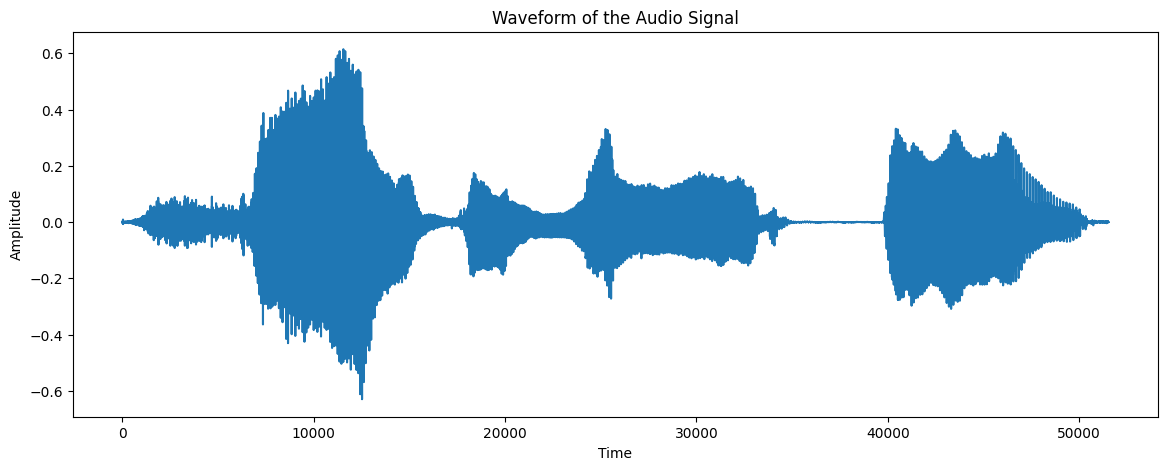

In [ ]:
# Plot the waveform
plt.figure(figsize=(14, 5))
plt.plot(sample_signal)
plt.title('Waveform of the Audio Signal')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
def extract_mfcc_matrix(signal, sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH):
    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=n_fft,
        hop_length=hop_length
    )
    return mfcc

In [ ]:
sample_path = df.iloc[0]["path"]
sample_signal, sample_sr = load_audio(sample_path)

sample_mfcc = extract_mfcc_matrix(sample_signal, sample_sr)

print("Sample path :", sample_path)
print("Signal shape:", sample_signal.shape)
print("MFCC shape  :", sample_mfcc.shape)

Sample path : /content/drive/MyDrive/MIDTERM TK AI/DATASET/YAF_angry/YAF_bar_angry.wav
Signal shape: (51542,)
MFCC shape  : (40, 101)


In [ ]:
TARGET_FRAMES = 128

def fix_mfcc_frames(mfcc, target_frames=TARGET_FRAMES):
    current_frames = mfcc.shape[1]

    if current_frames < target_frames:
        pad_width = target_frames - current_frames
        mfcc_fixed = np.pad(mfcc, ((0, 0), (0, pad_width)), mode="constant")
    else:
        mfcc_fixed = mfcc[:, :target_frames]

    return mfcc_fixed

In [ ]:
sample_mfcc_fixed = fix_mfcc_frames(sample_mfcc)

print("MFCC asli :", sample_mfcc.shape)
print("MFCC fixed:", sample_mfcc_fixed.shape)

MFCC asli : (40, 101)
MFCC fixed: (40, 128)


In [ ]:
mfcc_features = []
labels = []
# genders = []
file_paths = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    try:
        signal, sr = load_audio(row["path"])
        mfcc = extract_mfcc_matrix(signal, sr)
        mfcc = fix_mfcc_frames(mfcc, TARGET_FRAMES)

        # transpose agar jadi (time_steps, n_mfcc)
        mfcc = mfcc.T

        mfcc_features.append(mfcc)
        labels.append(row["emotion"])
        # genders.append(row["gender"])
        file_paths.append(row["path"])

    except Exception as e:
        print(f"Gagal memproses: {row['path']} | Error: {e}")

100%|██████████| 2800/2800 [24:17<00:00,  1.92it/s]


In [ ]:
X_mfcc = np.array(mfcc_features)
y_mfcc = np.array(labels)
# gender_mfcc = np.array(genders)
path_mfcc = np.array(file_paths)

print("X_mfcc shape :", X_mfcc.shape)
print("y_mfcc shape :", y_mfcc.shape)
print("Contoh shape satu sample:", X_mfcc[0].shape)

X_mfcc shape : (2800, 128, 40)
y_mfcc shape : (2800,)
Contoh shape satu sample: (128, 40)


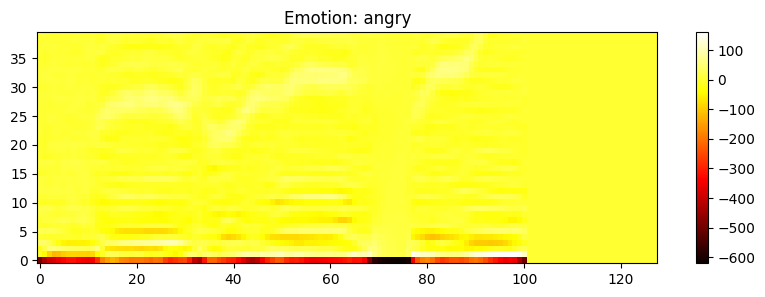

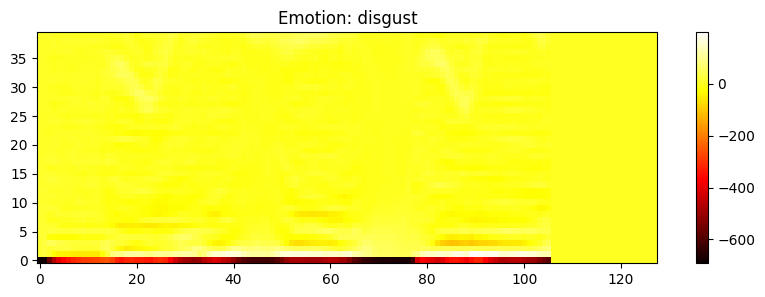

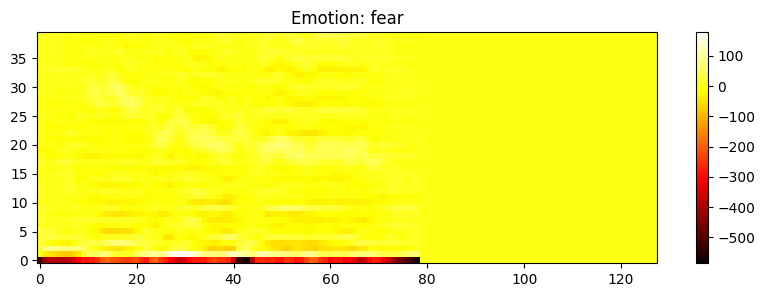

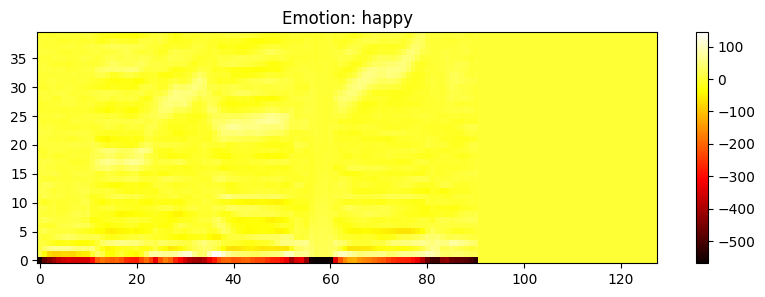

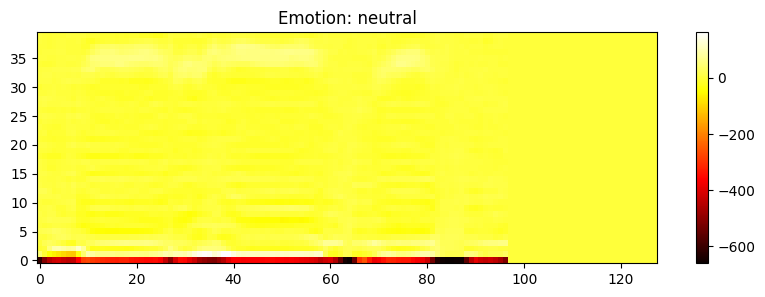

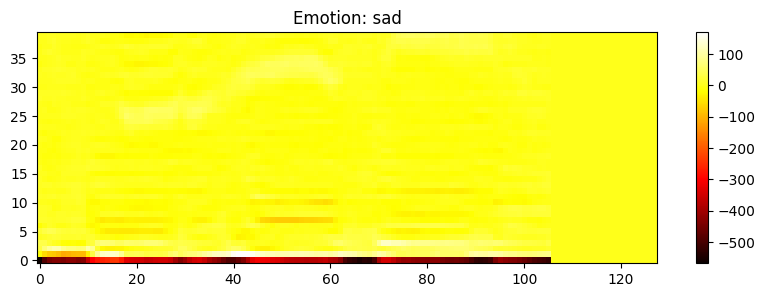

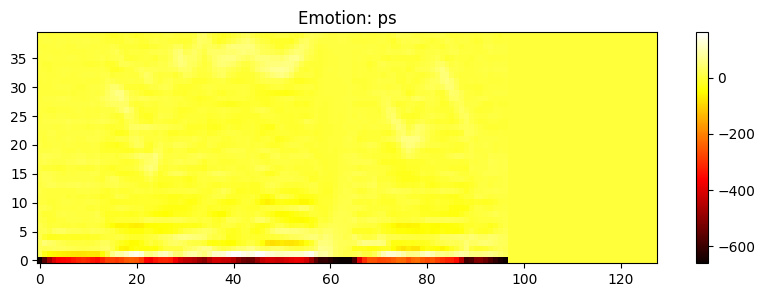

In [ ]:
# ambil 1 sample per emosi
shown = set()

for i in range(len(y_mfcc)):
    label = y_mfcc[i]

    if label not in shown:
        mfcc_vis = X_mfcc[i].T

        plt.figure(figsize=(10, 3))
        plt.imshow(mfcc_vis, cmap='hot', aspect='auto', origin='lower')
        plt.title(f"Emotion: {label}")
        plt.colorbar()
        plt.show()

        shown.add(label)

    if len(shown) == len(set(y_mfcc)):
        break

CHROMA

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

SR            = 22050
HOP_LENGTH    = 512
DURATION      = 2
TARGET_FRAMES = 128
N_CHROMA      = 12

In [ ]:
def extract_chroma(file_path):
    try:
        y, sr = librosa.load(file_path, sr=SR, duration=DURATION)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr, hop_length=HOP_LENGTH, n_chroma=N_CHROMA)

        if chroma.shape[1] < TARGET_FRAMES:
            pad_width = TARGET_FRAMES - chroma.shape[1]
            chroma = np.pad(chroma, ((0, 0), (0, pad_width)), mode='constant')
        else:
            chroma = chroma[:, :TARGET_FRAMES]

        return chroma  # shape: (12, 128)

    except Exception as e:
        print(f"[ERROR] {os.path.basename(file_path)}: {e}")
        return None

In [ ]:
chroma_data, labels = [], []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Ekstraksi Chroma"):
    matrix = extract_chroma(row['path'])
    if matrix is not None:
        chroma_data.append(matrix)
        labels.append(row['emotion'])

X_chroma = np.array(chroma_data)  # shape: (N, 12, 128)
y_labels = np.array(labels)

print(f"Shape X_chroma : {X_chroma.shape}")
print(f"Jumlah sampel  : {len(y_labels)}")
print(f"Kelas emosi    : {np.unique(y_labels)}")

np.save("/content/drive/MyDrive/MIDTERM TK AI/X_chroma.npy", X_chroma)
np.save("/content/drive/MyDrive/MIDTERM TK AI/y_labels.npy", y_labels)
print("\nTersimpan: X_chroma.npy, y_labels.npy")

Ekstraksi Chroma: 100%|██████████| 2800/2800 [00:46<00:00, 60.40it/s]


Shape X_chroma : (2800, 12, 128)
Jumlah sampel  : 2800
Kelas emosi    : ['angry' 'disgust' 'fear' 'happy' 'neutral' 'ps' 'sad']

Tersimpan: X_chroma.npy, y_labels.npy


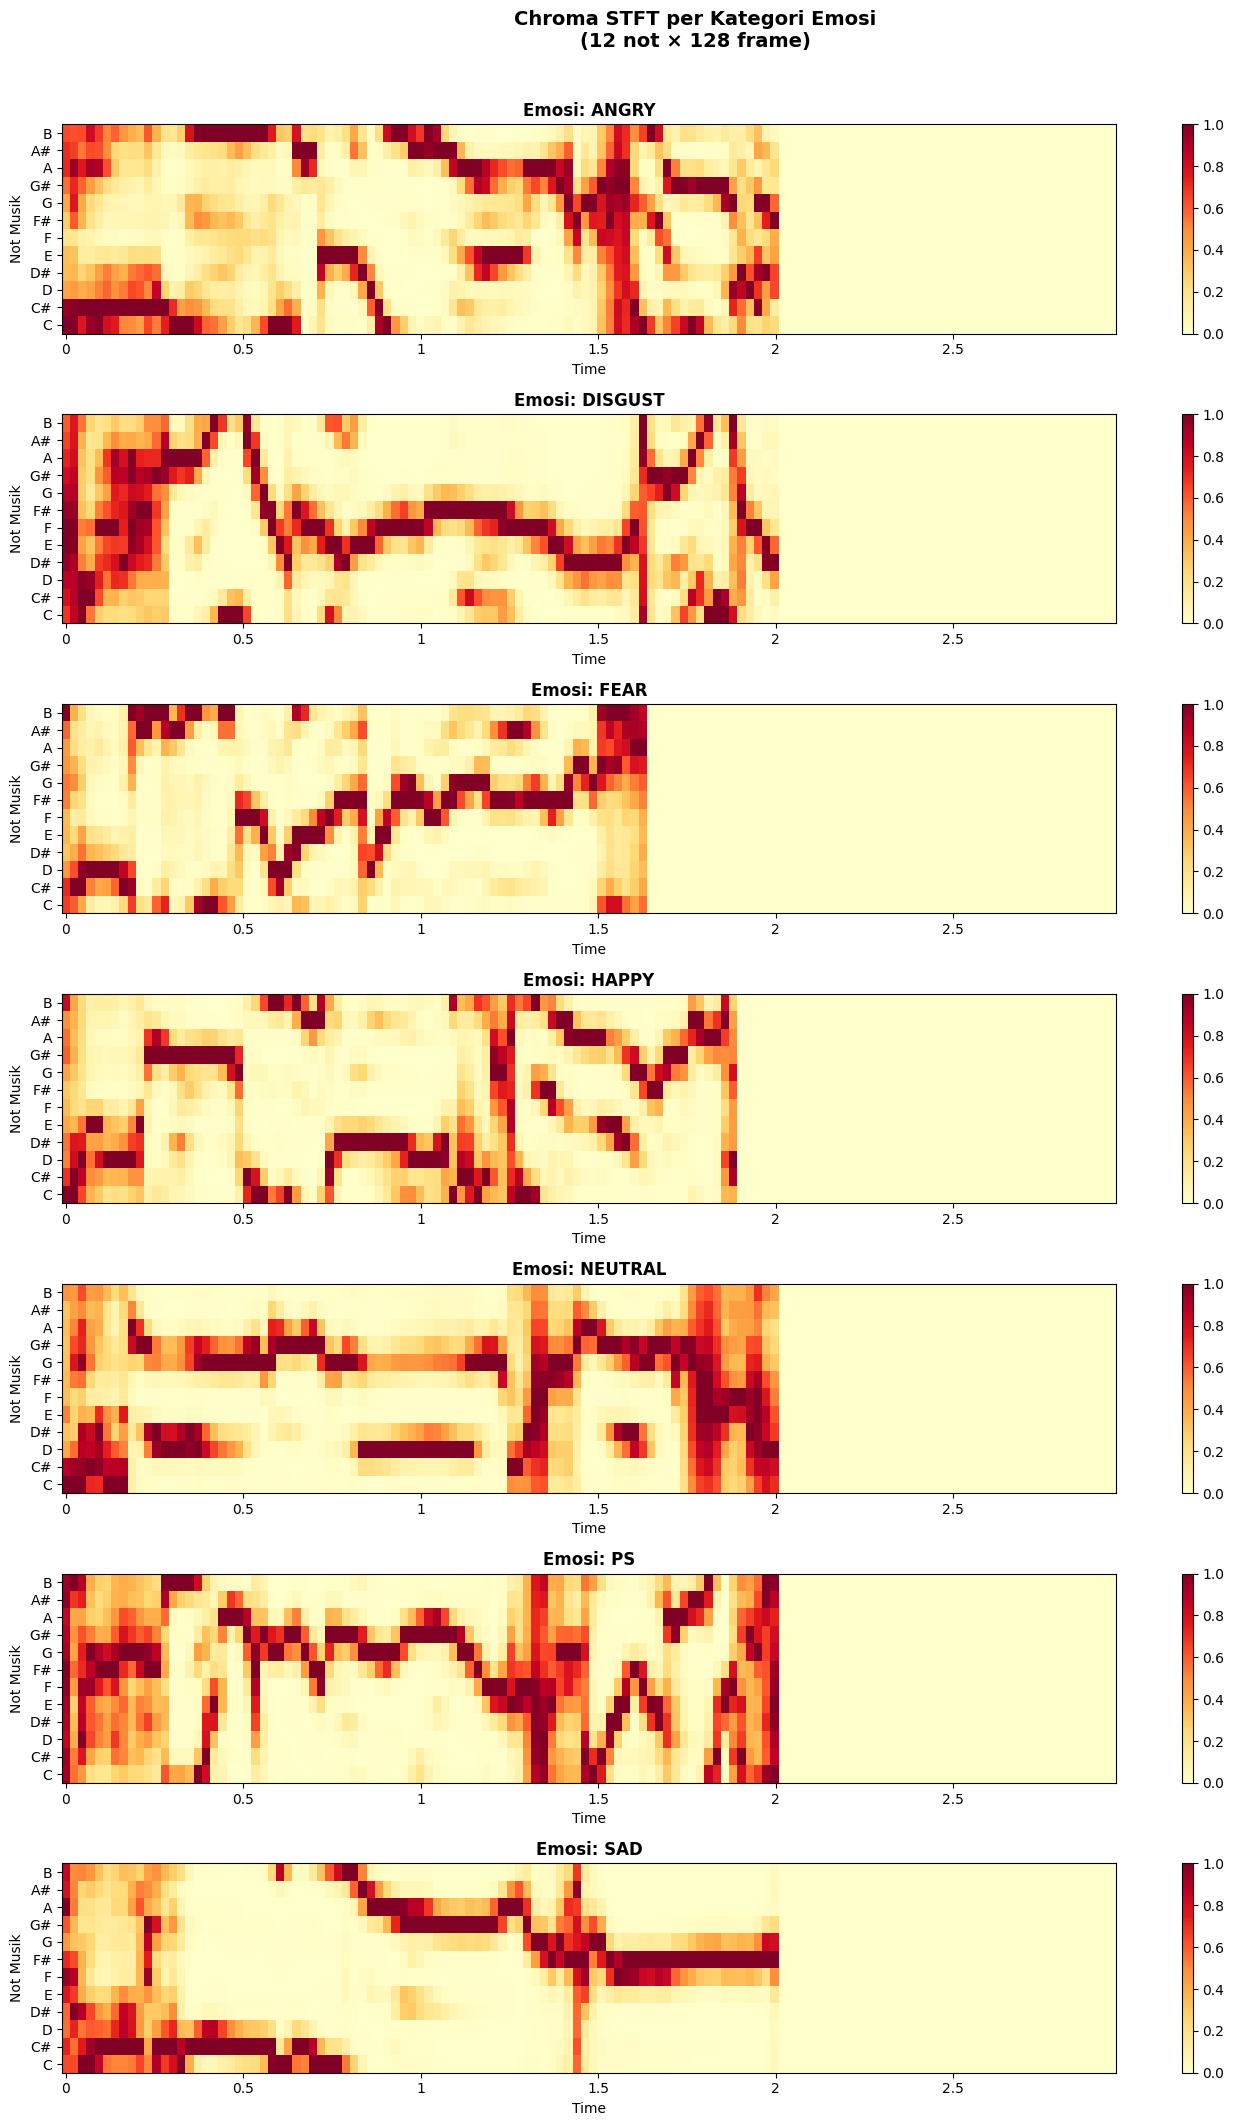

In [ ]:
notes    = ['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
emotions = np.unique(y_labels)
n_emotions = len(emotions)

fig, axes = plt.subplots(n_emotions, 1, figsize=(14, 3 * n_emotions))

for i, emotion in enumerate(emotions):
    # Ambil 1 sampel dari tiap emosi
    idx    = np.where(y_labels == emotion)[0][0]
    chroma = X_chroma[idx]  # shape: (12, 128)

    img = librosa.display.specshow(
        chroma,
        y_axis='chroma',
        x_axis='time',
        sr=SR,
        hop_length=HOP_LENGTH,
        ax=axes[i],
        cmap='YlOrRd'
    )
    axes[i].set_title(f"Emosi: {emotion.upper()}", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Not Musik")
    axes[i].set_yticks(range(N_CHROMA))
    axes[i].set_yticklabels(notes)
    fig.colorbar(img, ax=axes[i])

plt.suptitle("Chroma STFT per Kategori Emosi\n(12 not × 128 frame)",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

MEL SPECTOGRAM

In [ ]:
def extract_mel_spectrogram(file_path, max_len=128):
    try:
        audio, sr = librosa.load(file_path, sr=22050)

        # Mel Spectrogram
        mel = librosa.feature.melspectrogram(
            y=audio,
            sr=sr,
            n_mels=128
        )

        # Convert ke dB (biar lebih representatif)
        mel_db = librosa.power_to_db(mel, ref=np.max)

        # Padding / Trimming biar semua sama panjang
        if mel_db.shape[1] < max_len:
            pad_width = max_len - mel_db.shape[1]
            mel_db = np.pad(mel_db, pad_width=((0,0),(0,pad_width)), mode='constant')
        else:
            mel_db = mel_db[:, :max_len]

        return mel_db

    except Exception as e:
        print("Error:", e)
        return None

In [ ]:
X_mel = []
y_labels = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    file_path = row["path"]
    label = row["emotion"]

    mel = extract_mel_spectrogram(file_path)

    if mel is not None:
        X_mel.append(mel)
        y_labels.append(label)

100%|██████████| 2800/2800 [00:45<00:00, 61.14it/s]


In [ ]:
X_mel = np.array(X_mel)
y_labels = np.array(y_labels)

print("Shape X:", X_mel.shape)

Shape X: (2800, 128, 128)


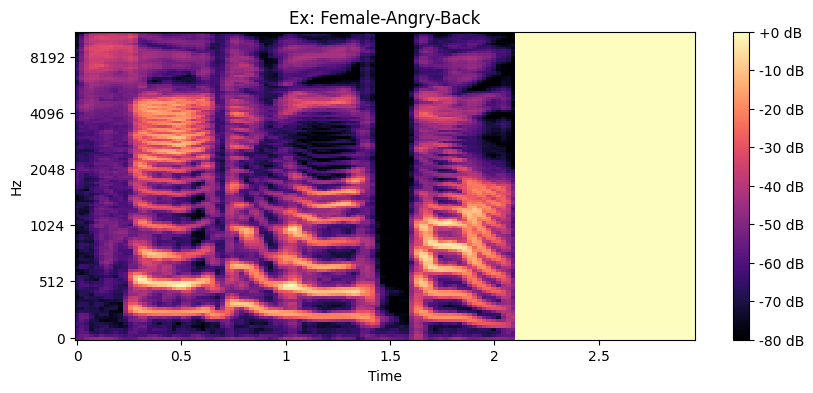

In [ ]:
import matplotlib.pyplot as plt
import librosa.display

sample = X_mel[0].squeeze()

plt.figure(figsize=(10,4))
librosa.display.specshow(sample, sr=22050, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Ex: Female-Angry-Back')
plt.show()

In [ ]:
X_chroma = np.transpose(X_chroma, (0, 2, 1))

In [ ]:
print(X_mfcc.shape)
print(X_mel.shape)
print(X_chroma.shape)

(2800, 128, 40)
(2800, 128, 128)
(2800, 128, 12)


# Baseline Model

ITERASI 2

In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_labels)
class_names = list(label_encoder.classes_)

print("Class names:", class_names)
print("Jumlah kelas:", len(class_names))

Class names: [np.str_('angry'), np.str_('disgust'), np.str_('fear'), np.str_('happy'), np.str_('neutral'), np.str_('ps'), np.str_('sad')]
Jumlah kelas: 7


In [ ]:
X_mfcc_flat = X_mfcc.reshape(X_mfcc.shape[0], -1)
X_mel_flat = X_mel.reshape(X_mel.shape[0], -1)
X_chroma_flat = X_chroma.reshape(X_chroma.shape[0], -1)

print("X_mfcc_flat   :", X_mfcc_flat.shape)
print("X_mel_flat    :", X_mel_flat.shape)
print("X_chroma_flat :", X_chroma_flat.shape)

X_mfcc_flat   : (2800, 5120)
X_mel_flat    : (2800, 16384)
X_chroma_flat : (2800, 1536)


In [ ]:
X_combined = np.concatenate([X_mfcc, X_mel, X_chroma], axis=2)
print("X_combined shape:", X_combined.shape)

X_combined_flat = X_combined.reshape(X_combined.shape[0], -1)
print("X_combined_flat shape:", X_combined_flat.shape)

X_combined shape: (2800, 128, 180)
X_combined_flat shape: (2800, 23040)


In [ ]:
np.save("/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1/X_combined.npy", X_combined)
np.save("/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1/y_labels_final.npy", y_labels)

In [ ]:
def train_evaluate_svm(X, y, model_name="SVM Feature"):
    # split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # model
    svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True)
    svm_model.fit(X_train_scaled, y_train)

    # prediksi
    y_pred = svm_model.predict(X_test_scaled)

    # metrik
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    print(f"=== {model_name} ===")
    print("Accuracy :", acc)
    print("Precision:", prec)
    print("Recall   :", rec)
    print("F1-score :", f1)
    print()
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {
        "model_name": model_name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1,
        "y_test": y_test,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "svm_model": svm_model,
        "scaler": scaler
    }

=== SVM - Combined Features ===
Accuracy : 0.9982142857142857
Precision: 0.998236331569665
Recall   : 0.9982142857142857
F1-score : 0.9982142159570966

              precision    recall  f1-score   support

       angry       1.00      1.00      1.00        80
     disgust       0.99      1.00      0.99        80
        fear       1.00      1.00      1.00        80
       happy       1.00      1.00      1.00        80
     neutral       1.00      1.00      1.00        80
          ps       1.00      0.99      0.99        80
         sad       1.00      1.00      1.00        80

    accuracy                           1.00       560
   macro avg       1.00      1.00      1.00       560
weighted avg       1.00      1.00      1.00       560



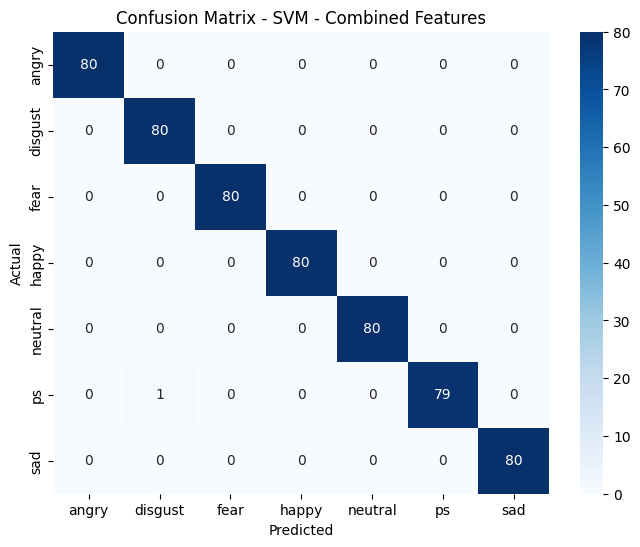

In [ ]:
result_combined = train_evaluate_svm(X_combined_flat, y_encoded, model_name="SVM - Combined Features")

In [ ]:
results_df = pd.DataFrame([
    {
        "Model": result_combined["model_name"],
        "Accuracy": result_combined["accuracy"],
        "Precision": result_combined["precision"],
        "Recall": result_combined["recall"],
        "F1-score": result_combined["f1_score"]
    }
])

results_df.sort_values(by="F1-score", ascending=False)

,Model,Accuracy,Precision,Recall,F1-score
0,SVM - Combined Features,0.998214,0.998236,0.998214,0.998214


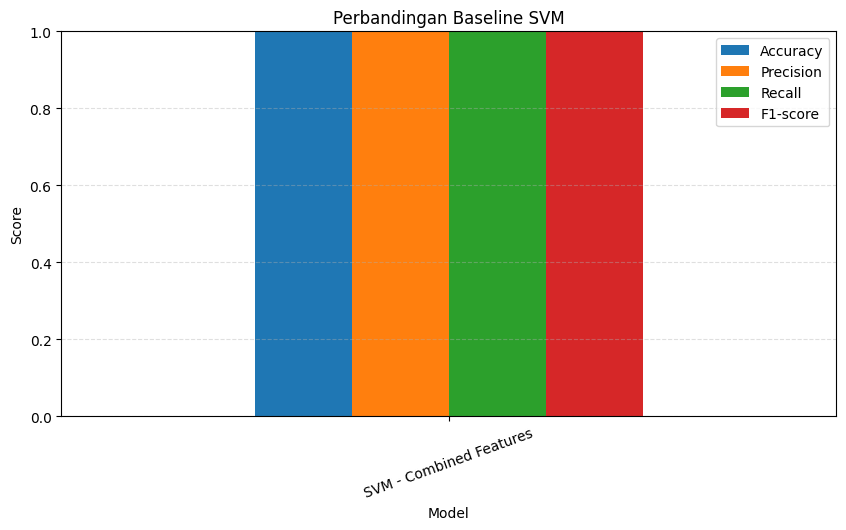

In [ ]:
results_df_plot = results_df.set_index("Model")
results_df_plot.plot(kind="bar", figsize=(10,5))
plt.title("Perbandingan Baseline SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

Cross Validation

In [ ]:
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']

svm_cv_pipeline_results = cross_validate(
    estimator=SVC(kernel='rbf', C=1.0, gamma='scale'),
    X=X_combined_flat,
    y=y_encoded,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

print("=== SVM Dengan Cross-Validation (5-Fold) ===")
print("Accuracy per fold :", svm_cv_pipeline_results['test_accuracy'])
print("Precision per fold:", svm_cv_pipeline_results['test_precision_weighted'])
print("Recall per fold   :", svm_cv_pipeline_results['test_recall_weighted'])
print("F1 per fold       :", svm_cv_pipeline_results['test_f1_weighted'])
print()

svm_cv_acc_mean = svm_cv_pipeline_results['test_accuracy'].mean()
svm_cv_acc_std = svm_cv_pipeline_results['test_accuracy'].std()

svm_cv_prec_mean = svm_cv_pipeline_results['test_precision_weighted'].mean()
svm_cv_rec_mean = svm_cv_pipeline_results['test_recall_weighted'].mean()
svm_cv_f1_mean = svm_cv_pipeline_results['test_f1_weighted'].mean()

print("Mean Accuracy :", svm_cv_acc_mean)
print("Std Accuracy  :", svm_cv_acc_std)
print("Mean Precision:", svm_cv_prec_mean)
print("Mean Recall   :", svm_cv_rec_mean)
print("Mean F1-score :", svm_cv_f1_mean)

=== SVM Dengan Cross-Validation (5-Fold) ===
Accuracy per fold : [0.98571429 0.98392857 0.98392857 0.97857143 0.98392857]
Precision per fold: [0.98616767 0.98403607 0.98422807 0.97888912 0.98446697]
Recall per fold   : [0.98571429 0.98392857 0.98392857 0.97857143 0.98392857]
F1 per fold       : [0.9857294  0.9839389  0.98395935 0.97863402 0.98394321]

Mean Accuracy : 0.9832142857142857
Std Accuracy  : 0.0024222607082590385
Mean Precision: 0.9835575786036254
Mean Recall   : 0.9832142857142857
Mean F1-score : 0.9832409762147012


#MODEL CNN

Experiment 1

In [ ]:
# X_combined = np.concatenate([X_mfcc, X_mel, X_chroma], axis=2)
print(X_combined.shape)

(2800, 128, 180)


In [ ]:
X_combined = np.expand_dims(X_combined, axis=-1)
print(X_combined.shape)

(2800, 128, 180, 1)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_cnn, X_test_cnn, y_train_cnn, y_test_cnn = train_test_split(
    X_combined,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(X_train_cnn.shape, X_test_cnn.shape)
print(y_train_cnn.shape, y_test_cnn.shape)

(2240, 128, 180, 1) (560, 128, 180, 1)
(2240,) (560,)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)
]

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, LSTM, Dense, Dropout,
    Reshape, BatchNormalization
)

model = Sequential([
    Input(shape=(128, 180, 1)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Reshape((32, 45 * 64)),

    LSTM(64),

    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(class_names), activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 180, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 32, 2880)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │       753,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 777,735 (2.97 MB)

 Trainable params: 777,543 (2.97 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
history = model.fit(
    X_train_cnn, y_train_cnn,
    validation_split=0.2,
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.2958 - loss: 1.7207 - val_accuracy: 0.3438 - val_loss: 1.5604 - learning_rate: 0.0010
Epoch 2/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.3856 - loss: 1.4558 - val_accuracy: 0.4420 - val_loss: 1.2741 - learning_rate: 0.0010
Epoch 3/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.4057 - loss: 1.3661 - val_accuracy: 0.4420 - val_loss: 1.1914 - learning_rate: 0.0010
Epoch 4/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.4163 - loss: 1.2866 - val_accuracy: 0.5402 - val_loss: 1.1428 - learning_rate: 0.0010
Epoch 5/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.4961 - loss: 1.1981 - val_accuracy: 0.6473 - val_loss: 1.0526 - learning_rate: 0.0010
Epoch 6/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.5257 - loss: 1.1456 - val_accuracy: 0.6585 - val_loss: 0.9921 - learning_rate: 0.0010
Epoch 7/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.6306 - loss: 0.

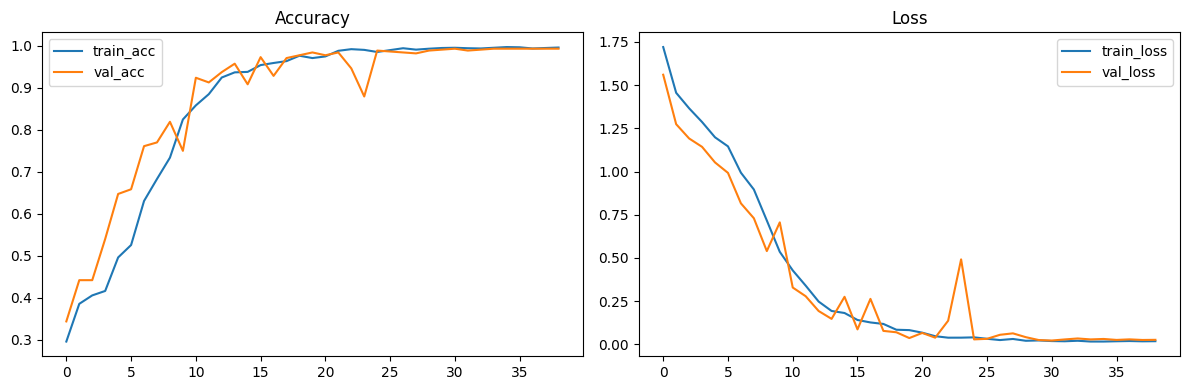

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import seaborn as sns

y_pred_prob = model.predict(X_test_cnn)
y_pred = np.argmax(y_pred_prob, axis=1)

acc = accuracy_score(y_test_cnn, y_pred)
prec = precision_score(y_test_cnn, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test_cnn, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test_cnn, y_pred, average='weighted', zero_division=0)

print("=== CNN-LSTM ===")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print()
print(classification_report(y_test_cnn, y_pred, target_names=class_names, zero_division=0))

18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 470ms/step
=== CNN-LSTM ===
Accuracy : 0.9946428571428572
Precision: 0.9947089947089948
Recall   : 0.9946428571428572
F1-score : 0.9946426478712896

              precision    recall  f1-score   support

       angry       1.00      0.99      0.99        80
     disgust       1.00      0.99      0.99        80
        fear       0.99      1.00      0.99        80
       happy       0.99      1.00      0.99        80
     neutral       0.99      1.00      0.99        80
          ps       1.00      1.00      1.00        80
         sad       1.00      0.99      0.99        80

    accuracy                           0.99       560
   macro avg       0.99      0.99      0.99       560
weighted avg       0.99      0.99      0.99       560



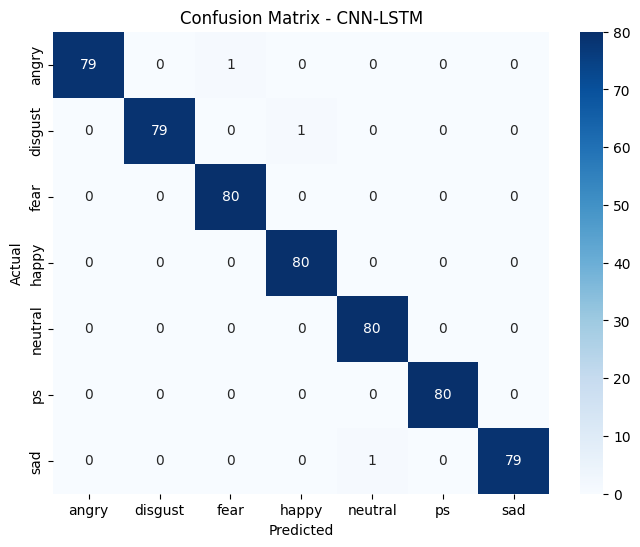

In [ ]:
cm = confusion_matrix(y_test_cnn, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - CNN-LSTM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
import os, joblib, json

output_dir = "/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1_iter2"
os.makedirs(output_dir, exist_ok=True)

# SVM
joblib.dump(result_combined, os.path.join(output_dir, "svm_pipeline.pkl"))
joblib.dump(svm_cv_pipeline_results, os.path.join(output_dir, "svm_cv_pipeline.pkl"))

# CNN — simpan weights saja (format ini kompatibel semua versi Keras)
model.save_weights(os.path.join(output_dir, "cnn_lstm_model.weights.h5"))

# label encoder & class names
joblib.dump(label_encoder, os.path.join(output_dir, "label_encoder.pkl"))
with open(os.path.join(output_dir, "class_names.json"), "w") as f:
    json.dump(class_names, f)

print("✅ Semua model berhasil disimpan")

Semua model dan metadata berhasil disimpan


# Perbandingan CNN-LSTM & Baseline

In [ ]:
comparison_all_df = pd.DataFrame([
    {
        "Model": "SVM (Tanpa CV)",
        "Accuracy": result_combined["accuracy"],
        "Precision": result_combined["precision"],
        "Recall": result_combined["recall"],
        "F1-score": result_combined["f1_score"]
    },
    {
        "Model": "SVM (5-Fold CV)",
        "Accuracy": svm_cv_acc_mean,
        "Precision": svm_cv_prec_mean,
        "Recall": svm_cv_rec_mean,
        "F1-score": svm_cv_f1_mean
    },
    {
        "Model": "CNN-LSTM",
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    }
])

comparison_all_df

,Model,Accuracy,Precision,Recall,F1-score
0,SVM (Tanpa CV),0.998214,0.998236,0.998214,0.998214
1,SVM (5-Fold CV),0.983214,0.983558,0.983214,0.983241
2,CNN-LSTM,0.994643,0.994709,0.994643,0.994643


In [ ]:
print("=== RINGKASAN HASIL ===")
print(f"SVM tanpa CV  : Accuracy = {result_combined["accuracy"]:.4f}, F1 = {result_combined["f1_score"]:.4f}")
print(f"SVM dengan CV : Accuracy = {svm_cv_acc_mean:.4f} ± {svm_cv_acc_std:.4f}, F1 = {svm_cv_f1_mean:.4f}")
print(f"CNN-LSTM      : Accuracy = {acc:.4f}, F1 = {f1:.4f}")

=== RINGKASAN HASIL ===
SVM tanpa CV  : Accuracy = 0.9982, F1 = 0.9982
SVM dengan CV : Accuracy = 0.9832 ± 0.0024, F1 = 0.9832
CNN-LSTM      : Accuracy = 0.9946, F1 = 0.9946


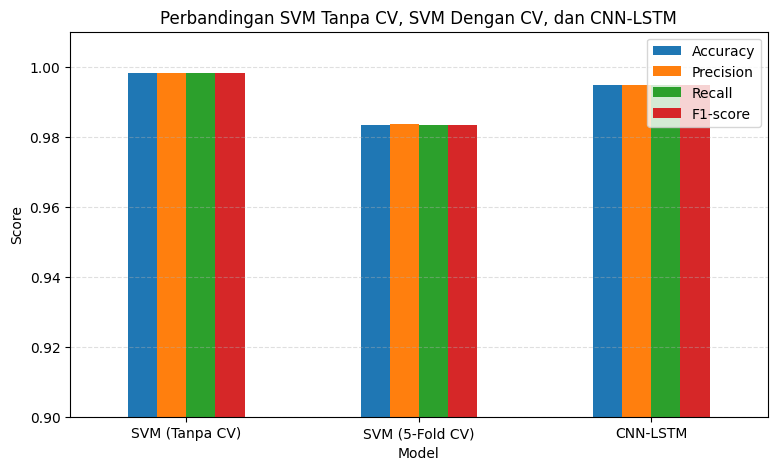

In [ ]:
comparison_plot = comparison_all_df.set_index("Model")

comparison_plot.plot(kind="bar", figsize=(9,5))
plt.title("Perbandingan SVM Tanpa CV, SVM Dengan CV, dan CNN-LSTM")
plt.ylabel("Score")
plt.ylim(0.9, 1.01)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

# DEMO

In [ ]:
model_path = '/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1/cnn_lstm_model.keras'
model = tf.keras.models.load_model(model_path)

In [ ]:
import numpy as np
import json # Import the json module

BASE = "/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1"

X_combined = np.load(f"{BASE}/X_combined.npy")
y_labels_final = np.load(f"{BASE}/y_labels_final.npy")

# Correctly load the JSON file
with open(f"{BASE}/class_names.json", "r") as f:
    class_names = json.load(f)

print("X_combined shape:", X_combined.shape)
print("y_labels_final shape:", y_labels_final.shape)
print("Class names:", class_names)

X_combined shape: (2800, 128, 180)
y_labels_final shape: (2800,)
Class names: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']


Upload file audio .wav untuk prediksi emosi:


Saving YAF_kick_happy.wav to YAF_kick_happy.wav

🎤 File: YAF_kick_happy.wav


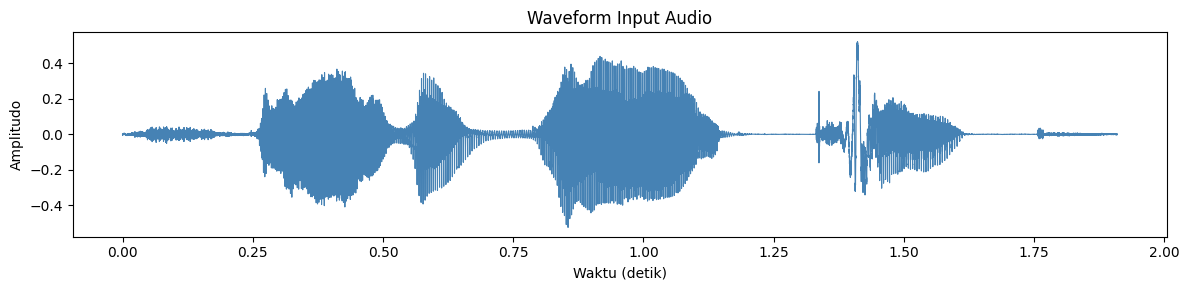

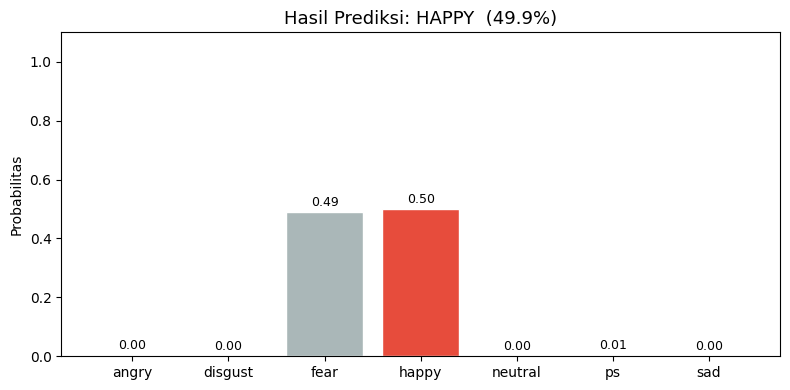


✅ Emosi Terdeteksi : HAPPY
   Kepercayaan      : 49.92%

   Detail probabilitas:
      angry |                             0.4%
    disgust |                             0.0%
       fear | ████████████               49.1%
      happy | ████████████               49.9% ◄
    neutral |                             0.0%
         ps |                             0.6%
        sad |                             0.0%


In [ ]:
from google.colab import files
import IPython.display as ipd

def extract_features_for_demo(file_path):
    """
    Ekstrak fitur gabungan (MFCC + Mel + Chroma) dari satu file audio,
    sesuai pipeline training: shape output (1, 128, 180, 1)
    """
    signal, sr = librosa.load(file_path, sr=SR)

    # --- MFCC → (128, 40) ---
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    if mfcc.shape[1] < TARGET_FRAMES:
        mfcc = np.pad(mfcc, ((0,0),(0, TARGET_FRAMES - mfcc.shape[1])), mode='constant')
    else:
        mfcc = mfcc[:, :TARGET_FRAMES]
    mfcc = mfcc.T  # (128, 40)

    # --- Mel Spectrogram → (128, 128) ---
    mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    if mel_db.shape[1] < TARGET_FRAMES:
        mel_db = np.pad(mel_db, ((0,0),(0, TARGET_FRAMES - mel_db.shape[1])), mode='constant')
    else:
        mel_db = mel_db[:, :TARGET_FRAMES]
    mel_db = mel_db.T  # (128, 128)

    # --- Chroma → (128, 12) ---
    chroma = librosa.feature.chroma_stft(y=signal, sr=sr, hop_length=HOP_LENGTH, n_chroma=12)
    if chroma.shape[1] < TARGET_FRAMES:
        chroma = np.pad(chroma, ((0,0),(0, TARGET_FRAMES - chroma.shape[1])), mode='constant')
    else:
        chroma = chroma[:, :TARGET_FRAMES]
    chroma = chroma.T  # (128, 12)

    # --- Gabungkan → (128, 180) ---
    combined = np.concatenate([mfcc, mel_db, chroma], axis=1)

    return combined[np.newaxis, :, :, np.newaxis]  # (1, 128, 180, 1)


def demo_predict(file_path):
    """Prediksi emosi dari satu file audio dan tampilkan hasilnya secara visual."""
    print(f"\n🎤 File: {os.path.basename(file_path)}")

    # Putar audio
    display(ipd.Audio(file_path))

    # Visualisasi waveform
    signal, sr = librosa.load(file_path, sr=SR)
    plt.figure(figsize=(12, 3))
    time_axis = np.linspace(0, len(signal) / sr, len(signal))
    plt.plot(time_axis, signal, color='steelblue', linewidth=0.8)
    plt.title("Waveform Input Audio")
    plt.xlabel("Waktu (detik)")
    plt.ylabel("Amplitudo")
    plt.tight_layout()
    plt.show()

    # Ekstrak fitur & prediksi
    features = extract_features_for_demo(file_path)
    probs    = model.predict(features, verbose=0)[0]
    pred_idx = np.argmax(probs)
    pred_label = class_names[pred_idx]

    # Bar chart probabilitas
    colors = ['#e74c3c' if i == pred_idx else '#aab7b8' for i in range(len(class_names))]
    plt.figure(figsize=(8, 4))
    bars = plt.bar(class_names, probs, color=colors, edgecolor='white')
    plt.title(f"Hasil Prediksi: {pred_label.upper()}  ({probs[pred_idx]*100:.1f}%)", fontsize=13)
    plt.ylabel("Probabilitas")
    plt.ylim(0, 1.1)
    for i, p in enumerate(probs):
        plt.text(i, p + 0.02, f"{p:.2f}", ha='center', fontsize=9)
    plt.tight_layout()
    plt.show()

    # Output teks
    print(f"\n✅ Emosi Terdeteksi : {pred_label.upper()}")
    print(f"   Kepercayaan      : {probs[pred_idx]*100:.2f}%")
    print("\n   Detail probabilitas:")
    for i, name in enumerate(class_names):
        bar = "█" * int(probs[i] * 25)
        marker = " ◄" if i == pred_idx else ""
        print(f"   {name:>8} | {bar:<25} {probs[i]*100:5.1f}%{marker}")

    return pred_label, probs


# ── Jalankan Demo ──────────────────────────────────────────────────
print("Upload file audio .wav untuk prediksi emosi:")
uploaded = files.upload()

for fname in uploaded.keys():
    demo_predict(fname)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Explanable AI

XAI - SHAP untuk SVM

In [ ]:
n = min(len(X_mfcc), len(X_mel), len(X_chroma))
X_mfcc_use   = X_mfcc[:n]
X_mel_use    = X_mel[:n]
X_chroma_use = X_chroma[:n]  # X_chroma is already in (N, 128, 12) shape from previous steps
y_labels     = y_labels[:n]

X_combined      = np.concatenate([X_mfcc_use, X_mel_use, X_chroma_use], axis=2)  # (N, 128, 180)
X_combined_flat = X_combined.reshape(X_combined.shape[0], -1)
X_cnn           = np.expand_dims(X_combined, axis=-1)  # (N, 128, 180, 1)

y_encoded = label_encoder.transform(y_labels)

# ── Split dengan random_state=42 yang sama persis ───────────────
X_train_flat, X_test_flat, y_train, y_test = train_test_split(
    X_combined_flat, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
X_train_cnn, X_test_cnn, _, _ = train_test_split(
    X_cnn, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Load the saved SVM pipeline to get the scaler
output_dir = "/content/drive/MyDrive/MIDTERM TK AI/saved_models_exp1"
svm_pipeline_loaded = joblib.load(os.path.join(output_dir, "svm_pipeline.pkl"))
svm_model = svm_pipeline_loaded["svm_model"]
scaler = svm_pipeline_loaded["scaler"]

# ── Pakai scaler dari saved model, BUKAN fit ulang ──────────────
X_train_scaled = scaler.transform(X_train_flat)   # scaler sudah di-load dari svm_pipeline.pkl
X_test_scaled  = scaler.transform(X_test_flat)

print("X_test_flat shape :", X_test_flat.shape)
print("X_test_cnn shape  :", X_test_cnn.shape)
print("✅ Data siap untuk SHAP")

X_test_flat shape : (560, 23040)
X_test_cnn shape  : (560, 128, 180, 1)
✅ Data siap untuk SHAP


In [ ]:
print("=" * 55)
print("  XAI — SHAP KernelExplainer untuk SVM")
print("=" * 55)

feat_names = [f"feat_{i}" for i in range(X_combined_flat.shape[1])]

background_svm = shap.kmeans(X_train_scaled, 50)

print("Menghitung SHAP values SVM (harap tunggu ±2-5 menit)...")
explainer_svm   = shap.KernelExplainer(svm_model.predict_proba, background_svm)
shap_values_svm = explainer_svm.shap_values(X_test_scaled[:30])

# ── Plot 1: Summary plot per kelas
for i, emotion in enumerate(class_names):
    plt.figure()
    shap.summary_plot(
        shap_values_svm[i], X_test_scaled[:30],
        feature_names=feat_names, plot_type="dot",
        max_display=20, show=False
    )
    plt.title(f"SHAP Summary — Emosi: {emotion.upper()}")
    plt.tight_layout()
    plt.show()

# ── Plot 2: Top-20 fitur global (rata-rata semua kelas)
mean_abs_svm = np.mean([np.mean(np.abs(sv), axis=0) for sv in shap_values_svm], axis=0)
top_idx      = np.argsort(mean_abs_svm)[::-1][:20]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in top_idx][::-1], mean_abs_svm[top_idx][::-1], color='steelblue')
plt.xlabel("Mean |SHAP Value|")
plt.title("Top 20 Fitur Paling Berpengaruh — SVM")
plt.tight_layout()
plt.show()

# ── Plot 3: Waterfall 1 sampel
sample_idx     = 0
pred_class_svm = np.argmax(svm_model.predict_proba(X_test_scaled[sample_idx:sample_idx+1])[0])
shap_single    = shap_values_svm[pred_class_svm][sample_idx]

top_n   = 20
idx_top = np.argsort(np.abs(shap_single))[::-1][:top_n]
vals    = shap_single[idx_top]
colors  = ['#e74c3c' if v > 0 else '#3498db' for v in vals]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in idx_top][::-1], vals[::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("SHAP Value")
plt.title(f"SHAP Kontribusi — Sampel #{sample_idx} | Prediksi: {class_names[pred_class_svm].upper()}")
plt.tight_layout()
plt.show()

  XAI — SHAP KernelExplainer untuk SVM
Menghitung SHAP values SVM (harap tunggu ±2-5 menit)...


  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
import os, json, warnings, gc
import numpy as np
import joblib, shap
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from tensorflow.keras.models import load_model
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

BASE = "/content/drive/MyDrive/MIDTERM TK AI"

# Load
model         = load_model(f"{BASE}/saved_models_exp1/cnn_lstm_model.keras")
svm_pipeline  = joblib.load(f"{BASE}/saved_models_exp1/svm_pipeline.pkl")
label_encoder = joblib.load(f"{BASE}/saved_models_exp1/label_encoder.pkl")
with open(f"{BASE}/saved_models_exp1/class_names.json") as f:
    class_names = json.load(f)

scaler = svm_pipeline["scaler"]

X_combined = np.load(f"{BASE}/saved_models_exp1/X_combined.npy")
y_encoded  = np.load(f"{BASE}/saved_models_exp1/y_labels_final.npy")

X_flat = X_combined.reshape(len(X_combined), -1)
X_cnn  = X_combined[:, :, :, np.newaxis]
del X_combined; gc.collect()

X_train_flat, X_test_flat, y_train, y_test = train_test_split(
    X_flat, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
X_train_cnn, X_test_cnn, _, _ = train_test_split(
    X_cnn, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
del X_flat, X_cnn; gc.collect()

X_train_scaled = scaler.transform(X_train_flat)
X_test_scaled  = scaler.transform(X_test_flat)
del X_test_flat; gc.collect()

print("✅ Data siap")

✅ Data siap


In [ ]:
# ── Train LinearSVC (cepat, ringan) ─────────────────────────────
# LinearSVC support LinearExplainer yang JAUH lebih hemat RAM dari KernelExplainer
print("Training LinearSVC (pengganti SVM RBF untuk SHAP)...")
linear_svc = LinearSVC(C=1.0, max_iter=2000)
linear_svc.fit(X_train_scaled, y_train)

from sklearn.metrics import accuracy_score
y_pred_lin = linear_svc.predict(X_test_scaled)
print(f"LinearSVC Accuracy: {accuracy_score(y_test, y_pred_lin):.4f}")
# (sebagai perbandingan saja, model utama tetap SVM RBF yang sudah disimpan)

Training LinearSVC (pengganti SVM RBF untuk SHAP)...


KeyboardInterrupt: 

In [ ]:
# ── SHAP LinearExplainer ─────────────────────────────────────────
feat_names = [f"feat_{i}" for i in range(X_test_scaled.shape[1])]

explainer_lin   = shap.LinearExplainer(linear_svc, X_train_scaled)
shap_values_lin = explainer_lin.shap_values(X_test_scaled[:50])
# LinearExplainer jauh lebih ringan, 50 sampel tidak masalah

del X_train_scaled; gc.collect()

# ── Plot 1: Global importance ────────────────────────────────────
mean_abs = np.mean(np.abs(shap_values_lin), axis=0)
top_idx  = np.argsort(mean_abs)[::-1][:20]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in top_idx][::-1], mean_abs[top_idx][::-1], color='steelblue')
plt.xlabel("Mean |SHAP Value|")
plt.title("Top 20 Fitur Paling Berpengaruh — LinearSVC")
plt.tight_layout(); plt.show()

# ── Plot 2: Summary dot plot ─────────────────────────────────────
shap.summary_plot(
    shap_values_lin, X_test_scaled[:50],
    feature_names=feat_names, plot_type="dot",
    max_display=20, show=False
)
plt.title("SHAP Summary — LinearSVC")
plt.tight_layout(); plt.show()

# ── Plot 3: Waterfall 1 sampel ───────────────────────────────────
sample_idx  = 0
shap_single = shap_values_lin[sample_idx]
idx_top     = np.argsort(np.abs(shap_single))[::-1][:20]
vals        = shap_single[idx_top]
colors      = ['#e74c3c' if v > 0 else '#3498db' for v in vals]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in idx_top][::-1], vals[::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
pred_label_lin = class_names[linear_svc.predict(X_test_scaled[sample_idx:sample_idx+1])[0]]
plt.title(f"SHAP Kontribusi — Sampel #{sample_idx} | Prediksi: {pred_label_lin.upper()}")
plt.tight_layout(); plt.show()

del shap_values_lin; gc.collect()

In [ ]:
print("SHAP SVM...")

feat_names = [f"feat_{i}" for i in range(X_test_flat.shape[1])]

# KMeans 30 cluster (lebih kecil dari 50, hemat RAM)
background_svm  = shap.kmeans(X_train_scaled, 30)
del X_train_scaled; gc.collect()  # langsung hapus setelah buat background

explainer_svm   = shap.KernelExplainer(svm_model.predict_proba, background_svm)

# Hanya 20 sampel (bukan 30) — cukup untuk interpretasi
shap_values_svm = explainer_svm.shap_values(X_test_scaled[:20])

# ── Plot global importance (rata-rata semua kelas) ───────────────
mean_abs_svm = np.mean([np.mean(np.abs(sv), axis=0) for sv in shap_values_svm], axis=0)
top_idx      = np.argsort(mean_abs_svm)[::-1][:20]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in top_idx][::-1], mean_abs_svm[top_idx][::-1], color='steelblue')
plt.xlabel("Mean |SHAP Value|")
plt.title("Top 20 Fitur Paling Berpengaruh — SVM")
plt.tight_layout(); plt.show()

# ── Plot waterfall 1 sampel ──────────────────────────────────────
sample_idx     = 0
pred_class_svm = np.argmax(svm_model.predict_proba(X_test_scaled[sample_idx:sample_idx+1])[0])
shap_single    = shap_values_svm[pred_class_svm][sample_idx]
idx_top        = np.argsort(np.abs(shap_single))[::-1][:20]
vals           = shap_single[idx_top]
colors         = ['#e74c3c' if v > 0 else '#3498db' for v in vals]

plt.figure(figsize=(9, 6))
plt.barh([feat_names[i] for i in idx_top][::-1], vals[::-1], color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.title(f"SHAP — Sampel #{sample_idx} | Prediksi: {class_names[pred_class_svm].upper()}")
plt.tight_layout(); plt.show()

del shap_values_svm; gc.collect()

SHAP SVM...


  0%|          | 0/20 [00:00<?, ?it/s]

XAI - SHAP untuk CNN-LSTM

In [ ]:
print("=" * 55)
print("  XAI — SHAP GradientExplainer untuk CNN-LSTM")
print("=" * 55)

background_cnn  = X_train_cnn[:100]
explainer_cnn   = shap.GradientExplainer(model, background_cnn)

print("Menghitung SHAP values CNN-LSTM (harap tunggu)...")
shap_values_cnn = explainer_cnn.shap_values(X_test_cnn[:10])

# ── Plot 1: Bar chart mean |SHAP| per kelas
mean_abs_per_class = [np.mean(np.abs(sv)) for sv in shap_values_cnn]
plt.figure(figsize=(8, 4))
plt.bar(class_names, mean_abs_per_class, color='teal')
plt.title("Rata-rata |SHAP| per Kelas Emosi — CNN-LSTM")
plt.ylabel("Mean |SHAP Value|")
plt.tight_layout()
plt.show()

# ── Plot 2: Heatmap SHAP pada spectrogram (1 sampel)
sample_idx   = 0
pred_proba   = model.predict(X_test_cnn[sample_idx:sample_idx+1], verbose=0)[0]
pred_class   = np.argmax(pred_proba)
true_label   = class_names[y_test[sample_idx]]
pred_label_c = class_names[pred_class]

shap_map = shap_values_cnn[pred_class][sample_idx, :, :, 0]  # (128, 180)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(X_test_cnn[sample_idx, :, :40, 0].T, aspect='auto', origin='lower', cmap='hot')
axes[0].set_title(f"Input MFCC\nLabel: {true_label.upper()} | Prediksi: {pred_label_c.upper()}")
axes[0].set_xlabel("Frame (Waktu)")
axes[0].set_ylabel("MFCC Koefisien")

vmax = np.max(np.abs(shap_map))
im   = axes[1].imshow(shap_map.T, aspect='auto', origin='lower',
                      cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f"SHAP Heatmap — Kelas: {pred_label_c.upper()}\nMerah=mendukung | Biru=menolak")
axes[1].set_xlabel("Frame (Waktu)")
axes[1].set_ylabel("Indeks Fitur (MFCC | Mel | Chroma)")
axes[1].axhline(y=40,  color='white',  linestyle='--', linewidth=1, label='MFCC/Mel')
axes[1].axhline(y=168, color='yellow', linestyle='--', linewidth=1, label='Mel/Chroma')
axes[1].legend(loc='upper right', fontsize=8)
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

# ── Plot 3: Kontribusi per frame waktu
shap_over_time = np.mean(np.abs(shap_map), axis=1)
plt.figure(figsize=(12, 3))
plt.plot(shap_over_time, color='darkorange', linewidth=1.5)
plt.fill_between(range(len(shap_over_time)), shap_over_time, alpha=0.3, color='orange')
plt.title(f"Kontribusi SHAP per Frame Waktu — Prediksi: {pred_label_c.upper()}")
plt.xlabel("Frame (Waktu)")
plt.ylabel("Mean |SHAP|")
plt.tight_layout()
plt.show()

# ── Plot 4: Kontribusi per grup fitur
shap_per_feat = np.mean(np.abs(shap_map), axis=0)
group_means   = {
    "MFCC\n(0-39)"      : shap_per_feat[:40].mean(),
    "Mel Spec\n(40-167)" : shap_per_feat[40:168].mean(),
    "Chroma\n(168-179)"  : shap_per_feat[168:].mean(),
}

plt.figure(figsize=(6, 4))
plt.bar(group_means.keys(), group_means.values(), color=['#e67e22', '#2980b9', '#27ae60'])
plt.title(f"Kontribusi per Grup Fitur — Prediksi: {pred_label_c.upper()}")
plt.ylabel("Mean |SHAP Value|")
plt.tight_layout()
plt.show()

dominant = max(group_means, key=group_means.get)
print("\n📌 Interpretasi:")
print(f"   Fitur dominan   : {dominant.replace(chr(10), ' ')}")
print(f"   Frame tertinggi : Frame {np.argmax(shap_over_time)}")
print(f"   Prediksi        : {pred_label_c.upper()} ({pred_proba[pred_class]*100:.1f}%)")

In [ ]:
print("SHAP CNN-LSTM...")

background_cnn  = X_train_cnn[:50]   # 50 bukan 100
del X_train_cnn; gc.collect()

explainer_cnn   = shap.GradientExplainer(model, background_cnn)
shap_values_cnn = explainer_cnn.shap_values(X_test_cnn[:5])  # 5 sampel saja

# ── Bar chart per kelas ──────────────────────────────────────────
mean_abs_per_class = [np.mean(np.abs(sv)) for sv in shap_values_cnn]
plt.figure(figsize=(8, 4))
plt.bar(class_names, mean_abs_per_class, color='teal')
plt.title("Rata-rata |SHAP| per Kelas — CNN-LSTM")
plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

# ── Heatmap 1 sampel ────────────────────────────────────────────
sample_idx   = 0
pred_proba   = model.predict(X_test_cnn[sample_idx:sample_idx+1], verbose=0)[0]
pred_class   = np.argmax(pred_proba)
pred_label_c = class_names[pred_class]
true_label   = class_names[y_test[sample_idx]]

shap_map = shap_values_cnn[pred_class][sample_idx, :, :, 0]  # (128, 180)
vmax     = np.max(np.abs(shap_map))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(X_test_cnn[sample_idx,:,:40,0].T, aspect='auto', origin='lower', cmap='hot')
axes[0].set_title(f"Input MFCC | Label: {true_label.upper()} | Pred: {pred_label_c.upper()}")
axes[0].set_xlabel("Frame"); axes[0].set_ylabel("MFCC Koefisien")

im = axes[1].imshow(shap_map.T, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f"SHAP Heatmap — {pred_label_c.upper()}")
axes[1].axhline(y=40,  color='white',  linestyle='--', linewidth=1, label='MFCC/Mel')
axes[1].axhline(y=168, color='yellow', linestyle='--', linewidth=1, label='Mel/Chroma')
axes[1].legend(loc='upper right', fontsize=8)
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

# ── Per frame & per grup fitur ───────────────────────────────────
shap_over_time = np.mean(np.abs(shap_map), axis=1)
plt.figure(figsize=(12, 3))
plt.plot(shap_over_time, color='darkorange', linewidth=1.5)
plt.fill_between(range(128), shap_over_time, alpha=0.3, color='orange')
plt.title(f"Kontribusi per Frame — {pred_label_c.upper()}")
plt.xlabel("Frame"); plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

shap_per_feat = np.mean(np.abs(shap_map), axis=0)
group_means   = {
    "MFCC (0-39)"      : shap_per_feat[:40].mean(),
    "Mel Spec (40-167)" : shap_per_feat[40:168].mean(),
    "Chroma (168-179)"  : shap_per_feat[168:].mean(),
}
plt.figure(figsize=(6, 4))
plt.bar(group_means.keys(), group_means.values(), color=['#e67e22','#2980b9','#27ae60'])
plt.title(f"Kontribusi per Grup Fitur — {pred_label_c.upper()}")
plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

dominant = max(group_means, key=group_means.get)
print(f"\n📌 Fitur dominan   : {dominant}")
print(f"   Frame tertinggi : {np.argmax(shap_over_time)}")
print(f"   Prediksi        : {pred_label_c.upper()} ({pred_proba[pred_class]*100:.1f}%)")

In [ ]:
# ════════════════════════════════════════════════════════
#  SHAP CNN-LSTM — DeepExplainer (lebih ringan dari Gradient)
# ════════════════════════════════════════════════════════
import tensorflow as tf

background_cnn  = X_train_cnn[:30]   # cukup 30
del X_train_cnn; gc.collect()

explainer_cnn   = shap.DeepExplainer(model, background_cnn)
shap_values_cnn = explainer_cnn.shap_values(X_test_cnn[:5])

# ── Plot 1: Bar per kelas ────────────────────────────────────────
mean_abs_per_class = [np.mean(np.abs(sv)) for sv in shap_values_cnn]
plt.figure(figsize=(8, 4))
plt.bar(class_names, mean_abs_per_class, color='teal')
plt.title("Rata-rata |SHAP| per Kelas — CNN-LSTM")
plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

# ── Plot 2: Heatmap 1 sampel ─────────────────────────────────────
sample_idx   = 0
pred_proba   = model.predict(X_test_cnn[sample_idx:sample_idx+1], verbose=0)[0]
pred_class   = np.argmax(pred_proba)
pred_label_c = class_names[pred_class]
true_label   = class_names[y_test[sample_idx]]
shap_map     = shap_values_cnn[pred_class][sample_idx, :, :, 0]
vmax         = np.max(np.abs(shap_map))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(X_test_cnn[sample_idx,:,:40,0].T, aspect='auto', origin='lower', cmap='hot')
axes[0].set_title(f"Input MFCC | Label: {true_label.upper()} | Pred: {pred_label_c.upper()}")
axes[0].set_xlabel("Frame"); axes[0].set_ylabel("MFCC Koefisien")

im = axes[1].imshow(shap_map.T, aspect='auto', origin='lower',
                    cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f"SHAP Heatmap — {pred_label_c.upper()}")
axes[1].axhline(y=40,  color='white',  linestyle='--', linewidth=1, label='MFCC/Mel')
axes[1].axhline(y=168, color='yellow', linestyle='--', linewidth=1, label='Mel/Chroma')
axes[1].legend(loc='upper right', fontsize=8)
fig.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

# ── Plot 3: Per frame waktu ──────────────────────────────────────
shap_over_time = np.mean(np.abs(shap_map), axis=1)
plt.figure(figsize=(12, 3))
plt.plot(shap_over_time, color='darkorange', linewidth=1.5)
plt.fill_between(range(128), shap_over_time, alpha=0.3, color='orange')
plt.title(f"Kontribusi per Frame — {pred_label_c.upper()}")
plt.xlabel("Frame"); plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

# ── Plot 4: Per grup fitur ───────────────────────────────────────
shap_per_feat = np.mean(np.abs(shap_map), axis=0)
group_means   = {
    "MFCC (0-39)"       : shap_per_feat[:40].mean(),
    "Mel Spec (40-167)" : shap_per_feat[40:168].mean(),
    "Chroma (168-179)"  : shap_per_feat[168:].mean(),
}
plt.figure(figsize=(6, 4))
plt.bar(group_means.keys(), group_means.values(), color=['#e67e22','#2980b9','#27ae60'])
plt.title(f"Kontribusi per Grup Fitur — {pred_label_c.upper()}")
plt.ylabel("Mean |SHAP|"); plt.tight_layout(); plt.show()

dominant = max(group_means, key=group_means.get)
print(f"\n📌 Fitur dominan   : {dominant}")
print(f"   Frame tertinggi : {np.argmax(shap_over_time)}")
print(f"   Prediksi        : {pred_label_c.upper()} ({pred_proba[pred_class]*100:.1f}%)")